# 1, Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier

# 2. Load Dataset

In [2]:
# Define the path to your new dataset
csv_file_path2 = "All_features/UNSW_2018_IoT_Botnet_Full5pc_4.csv"
df = pd.read_csv(csv_file_path2)  # đổi tên file

print(df.shape)
print(df.head())
print(df.info())

C:\Users\owner\AppData\Local\Temp\ipykernel_28556\1843043468.py:3: DtypeWarning: Columns (7,9) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(csv_file_path2)  # đổi tên file


(668522, 46)
   pkSeqID         stime flgs  flgs_number proto  proto_number  \
0  3000001  1.528099e+09    e            1   udp             3   
1  3000002  1.528099e+09    e            1   udp             3   
2  3000003  1.528099e+09    e            1   udp             3   
3  3000004  1.528099e+09    e            1   udp             3   
4  3000005  1.528099e+09    e            1   udp             3   

             saddr sport          daddr dport  ...  AR_P_Proto_P_DstIP  \
0  192.168.100.147  6226  192.168.100.3    80  ...             1.09825   
1  192.168.100.147  6227  192.168.100.3    80  ...             1.09825   
2  192.168.100.147  6228  192.168.100.3    80  ...             1.09825   
3  192.168.100.147  6229  192.168.100.3    80  ...             1.09825   
4  192.168.100.147  6230  192.168.100.3    80  ...             1.09825   

   N_IN_Conn_P_DstIP N_IN_Conn_P_SrcIP  AR_P_Proto_P_Sport  \
0                100               100             1.09827   
1                100 

# 3, EDA

### 3.1 Check missing values

In [3]:
print(df.isnull().sum())

pkSeqID                             0
stime                               0
flgs                                0
flgs_number                         0
proto                               0
proto_number                        0
saddr                               0
sport                               0
daddr                               0
dport                               0
pkts                                0
bytes                               0
state                               0
state_number                        0
ltime                               0
seq                                 0
dur                                 0
mean                                0
stddev                              0
sum                                 0
min                                 0
max                                 0
spkts                               0
dpkts                               0
sbytes                              0
dbytes                              0
rate        

### 3.2 Distribution of attack categories

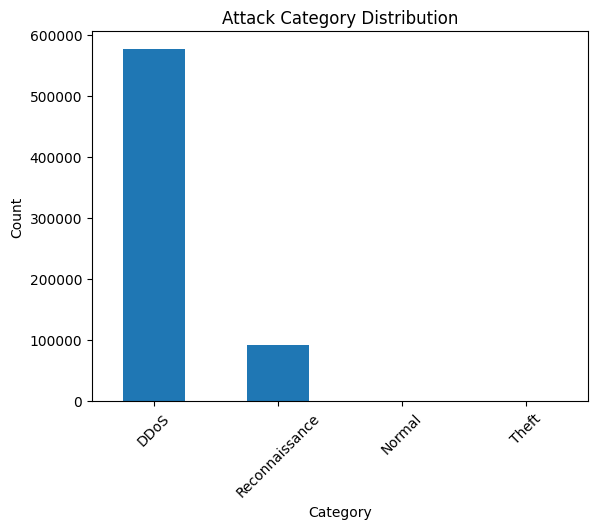

In [4]:
plt.figure()
df['category'].value_counts().plot(kind='bar')
plt.title("Attack Category Distribution")
plt.xlabel("Category")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

### 3.3 Attack vs Normal

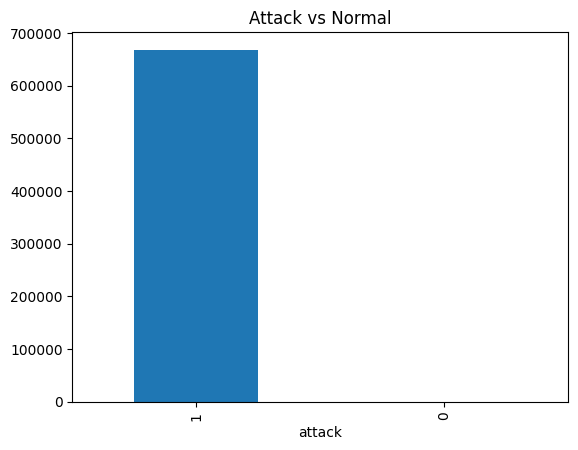

In [5]:
plt.figure()
df['attack'].value_counts().plot(kind='bar')
plt.title("Attack vs Normal")
plt.show()

# 4. Numeric Feature Analysis

### 4.1 Histogram

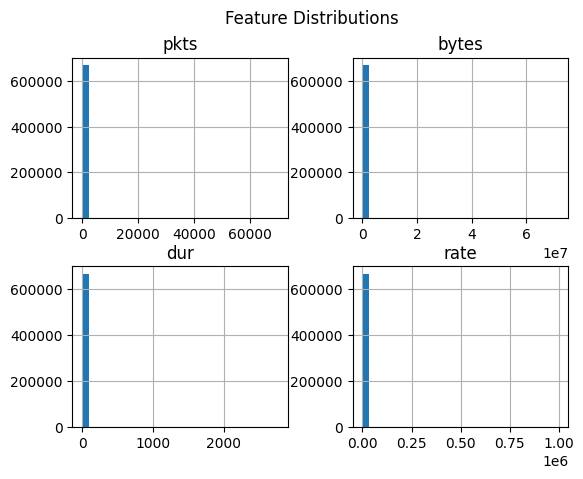

In [6]:
features = ['pkts', 'bytes', 'dur', 'rate']

df[features].hist(bins=30)
plt.suptitle("Feature Distributions")
plt.show()

### 4.2 Boxplot

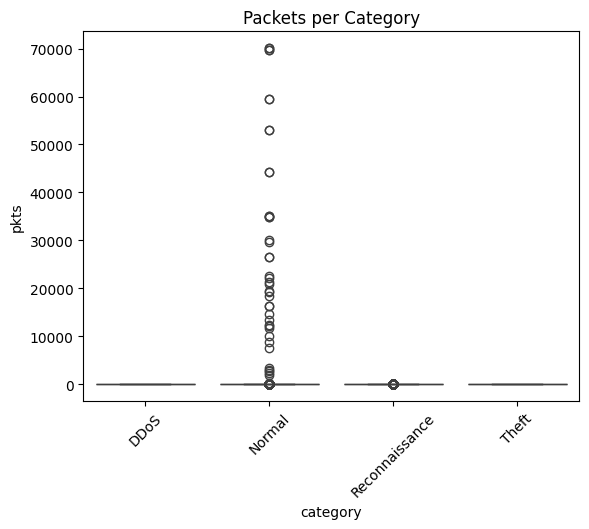

In [7]:
plt.figure()
sns.boxplot(x='category', y='pkts', data=df)
plt.xticks(rotation=45)
plt.title("Packets per Category")
plt.show()

### 4.3 Correlation heatmap

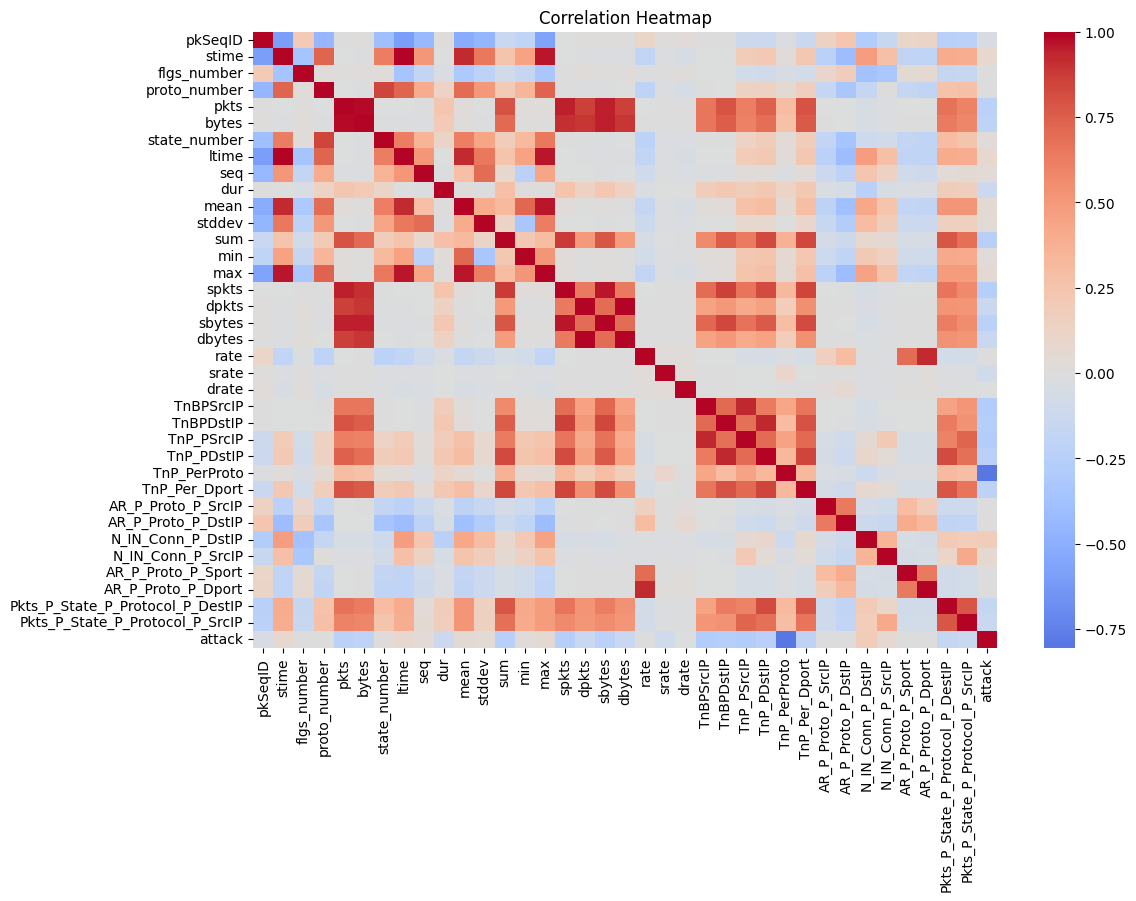

In [8]:
plt.figure(figsize=(12,8))
corr = df.select_dtypes(include=np.number).corr()

sns.heatmap(corr, cmap='coolwarm', center=0)
plt.title("Correlation Heatmap")
plt.show()

# 5. Data Preprocessing

### 5.1 Drop useless features

In [9]:
drop_cols = ['pkSeqID', 'saddr', 'daddr', 'stime', 'ltime', 'seq']
df = df.drop(columns=drop_cols, errors='ignore')

### 5.2 Encode label

In [10]:
print(df['category'].value_counts())
le = LabelEncoder()
df['category'] = le.fit_transform(df['category'])
print(df['category'].value_counts())

category
DDoS              576884
Reconnaissance     91082
Normal               477
Theft                 79
Name: count, dtype: int64
category
0    576884
2     91082
1       477
3        79
Name: count, dtype: int64


### 5.3 Encode categorical features

In [11]:
cat_cols = ['proto', 'state', 'flgs']

for col in cat_cols:
    if col in df.columns:
        df[col] = LabelEncoder().fit_transform(df[col])

# 6,Feature Selection

## 6.1, Split x, y

In [12]:
X = df.drop(columns=['category', 'subcategory', 'attack'], errors='ignore')
y = df['category']

In [13]:
from sklearn.preprocessing import LabelEncoder

for col in X.columns:
    if X[col].dtype == 'object':
        X[col] = LabelEncoder().fit_transform(X[col].astype(str))

### 🔹 6.2 Method 1: SelectKBest (ANOVA)

In [14]:
selector30 = SelectKBest(score_func=f_classif, k=30)
X_new = selector30.fit_transform(X, y)

selected_features30 = X.columns[selector30.get_support()]

print("Top 30 features (SelectKBest):")
print(selected_features30)

Top 30 features (SelectKBest):
Index(['flgs', 'flgs_number', 'proto', 'proto_number', 'dport', 'pkts',
       'bytes', 'state', 'state_number', 'mean', 'stddev', 'sum', 'min', 'max',
       'spkts', 'sbytes', 'TnBPSrcIP', 'TnBPDstIP', 'TnP_PSrcIP', 'TnP_PDstIP',
       'TnP_PerProto', 'TnP_Per_Dport', 'AR_P_Proto_P_SrcIP',
       'AR_P_Proto_P_DstIP', 'N_IN_Conn_P_DstIP', 'N_IN_Conn_P_SrcIP',
       'AR_P_Proto_P_Sport', 'AR_P_Proto_P_Dport',
       'Pkts_P_State_P_Protocol_P_DestIP', 'Pkts_P_State_P_Protocol_P_SrcIP'],
      dtype='object')


In [15]:
selector20 = SelectKBest(score_func=f_classif, k=20)
X_new = selector20.fit_transform(X, y)

selected_features20 = X.columns[selector20.get_support()]

print("Top 20 features (SelectKBest):")
print(selected_features20)

Top 20 features (SelectKBest):
Index(['flgs', 'flgs_number', 'proto', 'proto_number', 'dport', 'state',
       'state_number', 'mean', 'stddev', 'sum', 'min', 'max', 'TnP_PSrcIP',
       'TnP_PDstIP', 'TnP_PerProto', 'TnP_Per_Dport', 'AR_P_Proto_P_DstIP',
       'N_IN_Conn_P_DstIP', 'Pkts_P_State_P_Protocol_P_DestIP',
       'Pkts_P_State_P_Protocol_P_SrcIP'],
      dtype='object')


In [16]:
selector = SelectKBest(score_func=f_classif, k=10)
X_new = selector.fit_transform(X, y)

selected_features = X.columns[selector.get_support()]
 
print("Top 10 features (SelectKBest):")
print(selected_features)

Top 10 features (SelectKBest):
Index(['proto', 'proto_number', 'dport', 'state', 'state_number', 'mean',
       'stddev', 'max', 'TnP_PerProto', 'N_IN_Conn_P_DstIP'],
      dtype='object')


### 🔹 6.3 Method 2: Random Forest Importance

In [17]:
rf = RandomForestClassifier(n_estimators=50, random_state=42)
rf.fit(X, y)

importances = pd.Series(rf.feature_importances_, index=X.columns)
importances = importances.sort_values(ascending=False)

print(importances.head(10))

sum                                 0.140830
stddev                              0.137096
dur                                 0.119206
mean                                0.099936
spkts                               0.072690
max                                 0.067974
Pkts_P_State_P_Protocol_P_DestIP    0.054893
pkts                                0.053673
TnP_PerProto                        0.038105
TnP_Per_Dport                       0.038098
dtype: float64


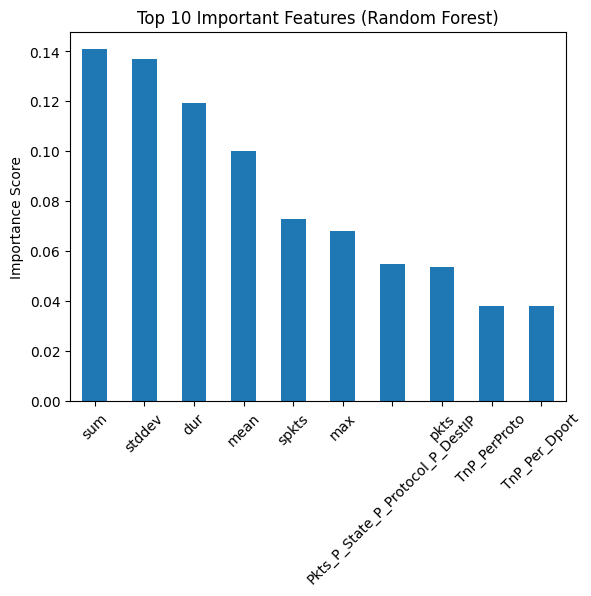

In [18]:
plt.figure()
importances.head(10).plot(kind='bar')
plt.title("Top 10 Important Features (Random Forest)")
plt.ylabel("Importance Score")
plt.xticks(rotation=45)
plt.show()

In [19]:
top_features = importances.head(10).index
X_selected = X[top_features]
print("Selected features based on Random Forest importance:")
print(X_selected.columns)

Selected features based on Random Forest importance:
Index(['sum', 'stddev', 'dur', 'mean', 'spkts', 'max',
       'Pkts_P_State_P_Protocol_P_DestIP', 'pkts', 'TnP_PerProto',
       'TnP_Per_Dport'],
      dtype='object')


In [20]:
print(X_selected.head())

        sum    stddev        dur     mean  spkts       max  \
0  11.73138  1.367803  13.657889  3.91046     15  4.884452   
1  11.73138  1.367802  13.657889  3.91046     15  4.884452   
2  11.73138  1.367802  13.657889  3.91046     15  4.884452   
3  11.73138  1.367802  13.657889  3.91046     15  4.884452   
4  11.73138  1.367803  13.657889  3.91046     15  4.884453   

   Pkts_P_State_P_Protocol_P_DestIP  pkts  TnP_PerProto  TnP_Per_Dport  
0                              1500    15          1500           1500  
1                              1500    15          1500           1500  
2                              1500    15          1500           1500  
3                              1500    15          1500           1500  
4                              1500    15          1500           1500  


# 7, Split Train and Test set

In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# 8, Resamples

In [22]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

# 9, Cross-validation

In [23]:
from imblearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier

pipeline = Pipeline([
    ('smote', SMOTE()),
    ('model', RandomForestClassifier())
])

scores = cross_val_score(pipeline, X, y, cv=5, scoring='f1_macro')
print(scores.mean())

KeyboardInterrupt: 

# 10, Train Final Model

In [24]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(n_estimators=100, random_state=42)

# dùng data đã resample
model.fit(X_train_res, y_train_res)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [25]:
import time

start = time.time()
model.fit(X_train_res, y_train_res)
train_time = time.time() - start
print("Training time:", train_time)

Training time: 304.3922550678253


# 11, Prediction

In [26]:
start = time.time()
model.predict(X_test)
pred_time = time.time() - start

print("Prediction time:", pred_time)
print("Time per sample:", pred_time / len(X_test))

Prediction time: 0.35137224197387695
Time per sample: 2.6279663585795368e-06


In [31]:
import os

size = os.path.getsize("results/baseline_model.pkl") / (1024*1024)
print("Baseline Model size (MB):", size)

Baseline Model size (MB): 0.8722467422485352


In [ ]:
y_pred = model.predict(X_test)

# 12, Evaluate Model

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

print("=== Classification Report ===")
print(classification_report(y_test, y_pred))

print("=== Confusion Matrix ===")
print(confusion_matrix(y_test, y_pred))

=== Classification Report ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    115377
           1       1.00      1.00      1.00        95
           2       1.00      1.00      1.00     18217
           3       1.00      1.00      1.00        16

    accuracy                           1.00    133705
   macro avg       1.00      1.00      1.00    133705
weighted avg       1.00      1.00      1.00    133705

=== Confusion Matrix ===
[[115377      0      0      0]
 [     0     95      0      0]
 [     0      0  18217      0]
 [     0      0      0     16]]


# 13, Confusion matrix

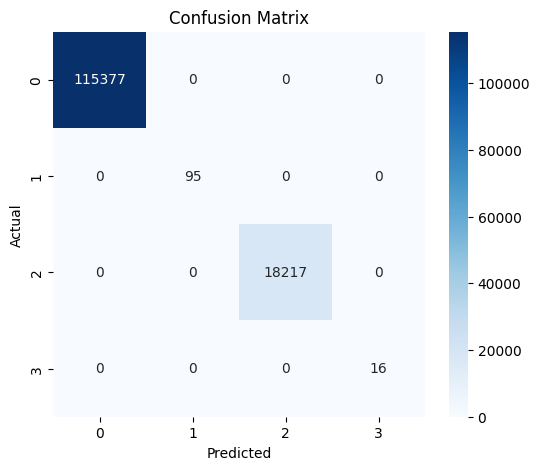

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=model.classes_,
            yticklabels=model.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# 14, Model Without SMOTE (baseline)

In [ ]:
model_base = RandomForestClassifier(n_estimators=100, random_state=42)
model_base.fit(X_train, y_train)

y_pred_base = model_base.predict(X_test)

print("=== WITHOUT SMOTE ===")
print(classification_report(y_test, y_pred_base))

=== WITHOUT SMOTE ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    115377
           1       1.00      1.00      1.00        95
           2       1.00      1.00      1.00     18217
           3       1.00      0.94      0.97        16

    accuracy                           1.00    133705
   macro avg       1.00      0.98      0.99    133705
weighted avg       1.00      1.00      1.00    133705



# 15, Comparing Feature Selection (lightweight model)

In [ ]:
# dùng top features
X_train_fs = X_train[selected_features]
X_test_fs = X_test[selected_features]

# SMOTE lại
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)

X_train_fs_res, y_train_fs_res = smote.fit_resample(X_train_fs, y_train)

# train
model_fs = RandomForestClassifier(n_estimators=100, random_state=42)
model_fs.fit(X_train_fs_res, y_train_fs_res)

# predict
y_pred_fs = model_fs.predict(X_test_fs)

print("=== FEATURE SELECTION ===")
print(classification_report(y_test, y_pred_fs))

=== FEATURE SELECTION ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    115377
           1       1.00      1.00      1.00        95
           2       1.00      1.00      1.00     18217
           3       1.00      1.00      1.00        16

    accuracy                           1.00    133705
   macro avg       1.00      1.00      1.00    133705
weighted avg       1.00      1.00      1.00    133705



# 16, Save result

In [ ]:
import os
import json
import joblib
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
RESULT_DIR = "results"
os.makedirs(RESULT_DIR, exist_ok=True)

In [ ]:
# classification report dạng dict
report_base = classification_report(y_test, y_pred_base, output_dict=True)

# lưu JSON
with open(f"{RESULT_DIR}/baseline_report.json", "w") as f:
    json.dump(report_base, f, indent=4)

# confusion matrix
cm_base = confusion_matrix(y_test, y_pred_base)
pd.DataFrame(cm_base).to_csv(f"{RESULT_DIR}/baseline_confusion_matrix.csv", index=False)

# lưu model
joblib.dump(model_base, f"{RESULT_DIR}/baseline_model.pkl")

['results/baseline_model.pkl']

In [ ]:
report_fs = classification_report(y_test, y_pred_fs, output_dict=True)

with open(f"{RESULT_DIR}/fs_report.json", "w") as f:
    json.dump(report_fs, f, indent=4)

cm_fs = confusion_matrix(y_test, y_pred_fs)
pd.DataFrame(cm_fs).to_csv(f"{RESULT_DIR}/fs_confusion_matrix.csv", index=False)

joblib.dump(model_fs, f"{RESULT_DIR}/fs_model.pkl")

['results/fs_model.pkl']

In [ ]:
pd.Series(selected_features).to_csv(f"{RESULT_DIR}/selected_features.csv", index=False)

In [ ]:
cv_results = {
    "cv_scores": scores.tolist(),
    "cv_mean": scores.mean(),
    "cv_std": scores.std()
}

with open(f"{RESULT_DIR}/cv_results.json", "w") as f:
    json.dump(cv_results, f, indent=4)

In [ ]:
summary = pd.DataFrame({
    "Model": ["Baseline", "Feature_Selection"],
    "F1_macro": [
        report_base["macro avg"]["f1-score"],
        report_fs["macro avg"]["f1-score"]
    ],
    "Accuracy": [
        report_base["accuracy"],
        report_fs["accuracy"]
    ]
})

summary.to_csv(f"{RESULT_DIR}/model_comparison.csv", index=False)
print(summary)

               Model  F1_macro  Accuracy
0           Baseline  0.991929  0.999993
1  Feature_Selection  1.000000  1.000000


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_cm(cm, title, filename):
    plt.figure(figsize=(6,4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.savefig(f"{RESULT_DIR}/{filename}")
    plt.close()

plot_cm(cm_base, "Baseline CM", "baseline_cm.png")
plot_cm(cm_fs, "Feature Selection CM", "fs_cm.png")

In [ ]:
print(X.columns)

Index(['flgs', 'flgs_number', 'proto', 'proto_number', 'sport', 'dport',
       'pkts', 'bytes', 'state', 'state_number', 'dur', 'mean', 'stddev',
       'sum', 'min', 'max', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate',
       'srate', 'drate', 'TnBPSrcIP', 'TnBPDstIP', 'TnP_PSrcIP', 'TnP_PDstIP',
       'TnP_PerProto', 'TnP_Per_Dport', 'AR_P_Proto_P_SrcIP',
       'AR_P_Proto_P_DstIP', 'N_IN_Conn_P_DstIP', 'N_IN_Conn_P_SrcIP',
       'AR_P_Proto_P_Sport', 'AR_P_Proto_P_Dport',
       'Pkts_P_State_P_Protocol_P_DestIP', 'Pkts_P_State_P_Protocol_P_SrcIP'],
      dtype='object')
